# 21 基于移动平均和指数平滑的时间序列预测

> **模块**：时间序列 ｜ **数据**：无（内置示例） ｜ **依赖**：numpy、pandas、matplotlib

## 1. 问题背景

时间序列预测法是一种定量分析方法，它是在时间序列变量分析的基础上，运用一定的数学方法建立预测模型，使时间趋势向外延伸，从而预测未来市场的发展变化趋势，确定变量预测值。

本实验主要介绍时间序列预测法中的移动平均和指数平滑。


## 2. 学习目标

- 掌握使用一次移动平均和二次移动平均预测时间序列
- 掌握使用一次指数平滑和二次指数平滑预测时间序列


## 3. 环境与数据

- Jupyter 开发环境
- Python 3.10


## 4. 方法与实现

### 4.1 移动平均

移动平均法根据时间序列逐项移动，一次计算包含一定项数的平均数，形成平均数时间序列，并据此对预测对象进行预测。

**特点：**
- 移动平均可以消除或减少时间序列数据受偶然性因素干扰而产生的随机变动影响。
- 移动平均法在短期预测中较准确，长期预测中效果较差。

常见的移动平均法可以有如下几种形式：
- 一次移动平均（Simple Moving Average，SMA）
- 二次移动平均（Double Moving Average，DMA）
- 加权移动平均（Weighted Moving Average，WMA）

#### 4.1.1 一次移动平均法

一次移动平均，也叫简单移动平均，计算前N期的算术平均值作为下一时期的预测值，即前几期数据的权重都相等（均为1/n）。

设观测序列为 $y_1,...,y_T$，取移动平均的项数 $N(N<T)$，一次移动平均值计算公式为：

$
M_t^{(1)}(N) = \frac{1}{N}(y_t+y_{t-1}+...+y_{t-N+1}) = \frac{1}{N} \sum_{i=0}^{N-1}{y_{t-i}}
$

$t+1$期的预测值为

$
\hat{y}_{t+1} = M_t^{(1)}(N)
$

即预测值等于前N期数据的平均值。简单移动平均只能适用于呈水平趋势的序列。当序列的变化不大（即方差比较小），没有明显的升降趋势和循环变动时，可以使用一次移动平均。

如果事物呈现某种上升或下降的趋势，不宜采用这种方法（参考移动平均的缺点）。

一次移动平均一般只能够预测下一期的序列值，更多期的预测将会产生更大的误差。

**例1**：以下为2000-2016年全国人均粮食产量（单位：公斤）数据。

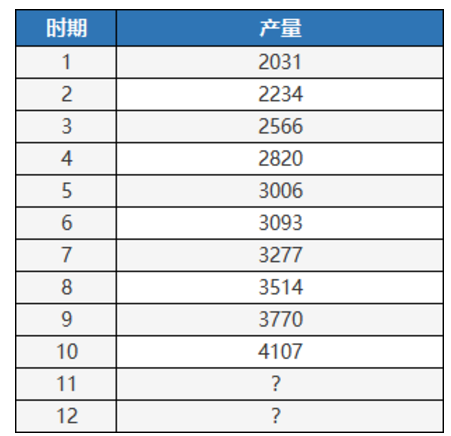

N取3和取5时，试用一次移动平均法预测下一年的人均粮食产量。


In [1]:
import numpy as np
import pandas as pd # 导入pandas库
import matplotlib.pyplot as plt
# 用来正常显示中文标签
plt.rcParams['font.sans-serif']=['SimHei'] 
# 正常显示负号
plt.rc('axes',unicode_minus=False)
# 创建时序数据
y = np.array([366.04,355.89,356.96,334.29,362.22,371.26,379.89,382.54,403.38,
            405.19,417.96,437.53,452.1,462.49,466.26,478.75,475.89])
# 自定义函数MoveAverage()利用一次移动平均预测
def MoveAverage(y,N):
    '''
    y:时序数据
    N:跨越期数
    '''
    # 先定义前n期数据
    Mt=[0]*N
    # 对于n+1期到预测期for循环
    for i in range(N+1,len(y)+2):
        # 计算N期平均作为下一期的预测值
        M=y[i-(N+1):i-1].mean()
        Mt.append(M)
    # 返回预测数据
    return np.array(Mt)
# N=3得到的预测数据
yt3 = MoveAverage(y,3) 
# N=3得到的预测数据
yt5 = MoveAverage(y,5)
# 将数据转换成DataFrame对象
# 将预测值新增一列
data = pd.DataFrame(np.append(y,0),
                    columns = ['人均粮食产量'],
                    index = np.arange(2000,2018))
data['预测值(N=3)'] = yt3
data['预测值(N=5)'] = yt5
data

,人均粮食产量,预测值(N=3),预测值(N=5)
2000,366.04,0.000000,0.000
2001,355.89,0.000000,0.000
2002,356.96,0.000000,0.000
2003,334.29,359.630000,0.000
2004,362.22,349.046667,0.000
2005,371.26,351.156667,355.080
2006,379.89,355.923333,356.124
2007,382.54,371.123333,360.924
2008,403.38,377.896667,366.040
2009,405.19,388.603333,379.858


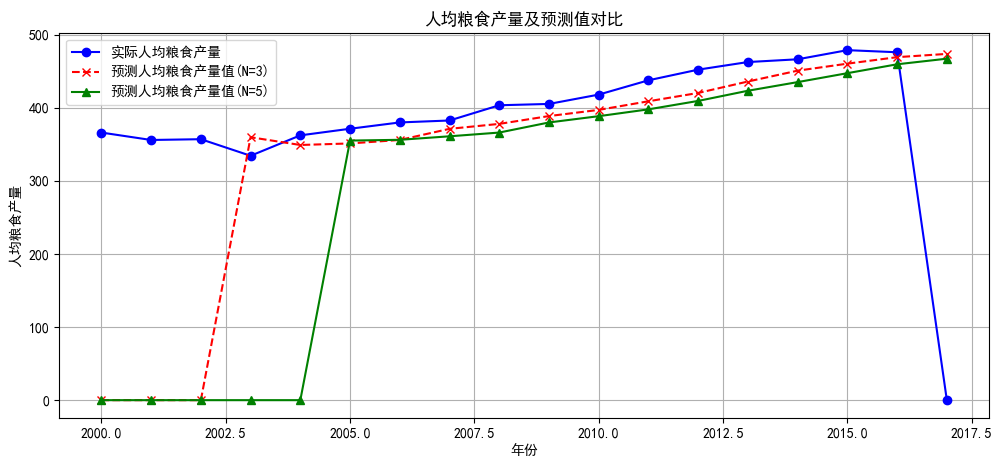

In [2]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plt.plot(data.index, data['人均粮食产量'], 'bo-', label='实际人均粮食产量')
plt.plot(data.index, data['预测值(N=3)'], 'rx--', label='预测人均粮食产量值(N=3)')
plt.plot(data.index, data['预测值(N=5)'], 'g^-', label='预测人均粮食产量值(N=5)')

plt.title('人均粮食产量及预测值对比')
plt.xlabel('年份')
plt.ylabel('人均粮食产量')
plt.grid(True)
plt.legend()
plt.show()


一次移动平均法，预测标准误差为：

$$S = \sqrt{\frac{\sum_{t=N+1}^{T}{{(\hat{y}_t-y_t)}^2}}{T-N}}$$

In [3]:
s3 = np.sqrt(((y[3:]-yt3[3:-1])**2)/(len(y)-3)).mean()
s5 = np.sqrt(((y[5:]-yt5[5:-1])**2)/(len(y)-5)).mean()
print('N=3时,预测的标准误差:',s3)
print('N=5时,预测的标准误差:',s5)

N=3时,预测的标准误差: 5.439211708321024
N=5时,预测的标准误差: 8.532034165561855


实际数据经过移动平均后，随机波动明显减少。

移动平均经常用来平滑序列的波动。当使用移动平均后，序列就变得更加平滑，期数N越大，平滑效果就越好。当对序列进行平滑后，就容易看出序列的整体变化趋势，方便进一步采用其它合适的方法来拟合序列的长期趋势线。

#### 4.1.2 二次移动平均法

二次移动平均法是对一次移动平均数再次进行移动平均，并在两次移动平均的基础上建立预测模型对预测对象进行预测。

设观测序列为 $y_1, y_2, \ldots, y_T$，取移动平均的项数 $N (N < T)$。

一次移动平均值计算公式为：

$$
M_t^{(1)}(N) = \frac{1}{N}(y_t + y_{t-1} + \ldots + y_{t-N+1}) = \frac{1}{N} \sum_{i=0}^{N-1} y_{t-i}

$$

二次移动平均值计算公式为：

$$
M_t^{(2)} = \frac{1}{N}(M_t^{(1)} + \ldots + M_{t-N+1}^{(1)})

$$

$t + T$ 期的预测值为：

$$
\hat{y}_{t+T} = a_t + b_t \cdot T

$$

- $$a_t = 2M_t^{(1)} - M_t^{(2)}$$
- $$b_t = \frac{2}{N-1}(M_t^{(1)} - M_t^{(2)})$$

**例2**.已知1991年到2002年某指标观测数据如下：

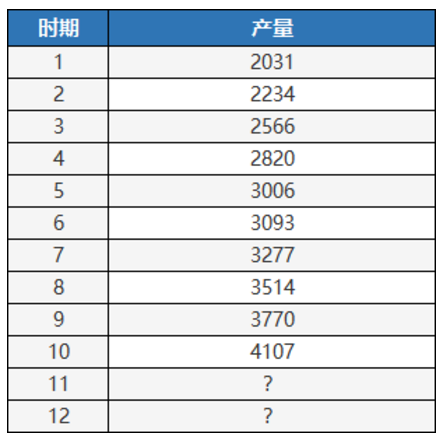

试用二次移动平均法计算2003年指标的数值（期数N=4）。


In [4]:
# 创建观测数据
y1 = np.array([38,45,35,49,70,43,46,55,45,65,64,43])
# 先计算一次移动平均
y1t4 = MoveAverage(y1,4) 
# 计算二次移动平均
y2t4 = MoveAverage(y1t4[4:],4) 
y2t4 = np.append(np.zeros(4),y2t4) 
df = pd.DataFrame(np.append(y1,0),
                    columns = ['观测值'],
                    index = np.arange(1991,2004))
df['一次移动平均(N=4)'] = y1t4
df['二次移动平均(N=4)'] = y2t4[:13]
df

,观测值,一次移动平均(N=4),二次移动平均(N=4)
1991,38,0.00,0.0000
1992,45,0.00,0.0000
1993,35,0.00,0.0000
1994,49,0.00,0.0000
1995,70,41.75,0.0000
1996,43,49.75,0.0000
1997,46,49.25,0.0000
1998,55,52.00,0.0000
1999,45,53.50,48.1875
2000,65,47.25,51.1250


$\hat{y}_{12+1} = a_{12}+b_{12}*1$
- $a_{12} = 2M_{12}^{(1)}-M_{12}^{(2)}=2*54.25-52.6875=55.8125$
- $b_{12} = \frac{2}{4-1}(M_{12}^{(1)}-M_{12}^{(2)})=2/3(54.25-52.6875)=1.04$

In [5]:
a12 = 2*54.25-52.6875
b12 = 2/3*(54.25-52.6875)
y2003 = a12+b12*1
print('2003年预测值为',y2003)

2003年预测值为 56.854166666666664


### 4.2 指数平滑

指数平滑法是一种特殊的加权平均法，是一次移动平均法的延伸。即对离预测期较近的历史数据给予较大的权数，权数由近到远按指数规律递减。

指数平滑法是对时间数据进行加工平滑，从而获得其变化规律与趋势。

指数平滑法根据本期的实际值和预测值，并借助平滑系数（α）进行加权平均计算，预测下一期的值。它对时间序列数据给予加权平滑，从而获得其规律变化与趋势。

#### 4.2.1 一次指数平滑

设观测序列为 $y_1, y_2, ..., y_t, ...$，$α$ 为加权系数，$0 < α < 1$，一次指数平滑的预测公式为：

$$
\hat{y}_{t+1} = S_t^{(1)} = αy_t + (1-α)S_{t-1}^{(1)} = S_{t-1}^{(1)} + α(y_t - S_{t-1}^{(1)})

$$

展开有：

$$
S_t^{(1)} = αy_t + α(1-α)y_{t-1} + α{(1-α)}^2y_{t-2} + ... + α{(1-α)}^{t-1}y_{1} = \sum_{j=0}^{t-1}{α{(1-α)}^{j}y_{t-j}}

$$

- $ S_t^{(1)} $：表示第 $ t $ 期一次指数平滑值
- $ \hat{y}_{t+1} $：表示第 $ t + 1 $ 期预测值

在进行指数平滑时，加权系数的选择是很重要的，$ α $ 的大小规定了在新预测中，新数据和原预测值所占的比重。

$ α $ 值越大，新数据所占的比重就越大，近期实际值对指数平滑值的影响越大。在实际应用中，应多取几个 $ α $ 值进行试算，看看哪个预测误差小，就采用哪个。

**例3**.某产品某年11期价格如下表，试用一次指数平滑法预测该产品第12期的价格。

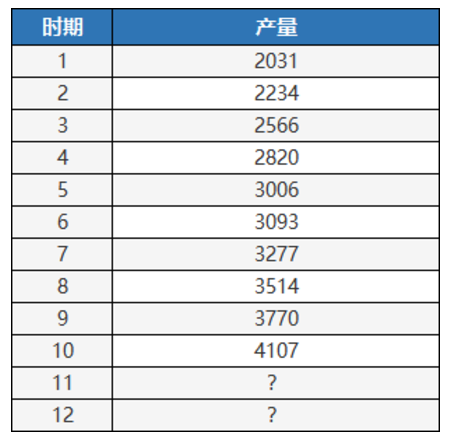


In [6]:
y2 = np.array([4.81,4.8,4.73,4.7,4.7,4.73,4.75,4.75,5.43,5.78,5.85])
# 自定义一个指数平滑函数
def ExpMove(y,a):
    '''
    y:时序数据
    a:平滑系数
    '''
    # 获取时序数据长度
    n=len(y)
    # 先创建一个全0向量
    M=np.zeros(n)
    # 设置初始值，S_0^(1) = (y1+y2)/2
    M[0]=(y[0]+y[1])/2
    # 循环
    for i in range(1,len(y)):
        # y^_t+1 = ay_t+(1-a)y^t
        M[i]=a*y[i-1]+(1-a)*M[i-1]
    return M
# α取0.2，0.5，0.8，比较标准误差
yt1 = ExpMove(y2,0.2)
yt2 = ExpMove(y2,0.5)
yt3 = ExpMove(y2,0.8)
df1 = pd.DataFrame(y2,
                    columns = ['观测值'],
                    index = np.arange(1,12))
df1['一次指数平滑（α=0.20'] = yt1
df1['一次指数平滑（α=0.50'] = yt2
df1['一次指数平滑（α=0.8)'] = yt3
df1

,观测值,一次指数平滑（α=0.20,一次指数平滑（α=0.50,一次指数平滑（α=0.8)
1,4.81,4.805000,4.805000,4.805000
2,4.80,4.806000,4.807500,4.809000
3,4.73,4.804800,4.803750,4.801800
4,4.70,4.789840,4.766875,4.744360
5,4.70,4.771872,4.733437,4.708872
6,4.73,4.757498,4.716719,4.701774
7,4.75,4.751998,4.723359,4.724355
8,4.75,4.751598,4.736680,4.744871
9,5.43,4.751279,4.743340,4.748974
10,5.78,4.887023,5.086670,5.293795


In [7]:
s1 = np.sqrt(((y2-yt1)**2).mean())
s2 = np.sqrt(((y2-yt2)**2).mean())
s3 = np.sqrt(((y2-yt3)**2).mean())
print("预测的标准误差分别为：",s1,s2,s3) 

预测的标准误差分别为： 0.4148362642161784 0.32164247683489516 0.25883473030674825


In [8]:
yh=0.8*y2[-1]+0.2*yt3[-1]
print("下一期的预测值为：",yh)

下一期的预测值为： 5.8165517935616


#### 4.2.2 二次指数平滑

一次指数平滑虽然克服了移动平均法的缺点，但当时间序列的变动出现直线趋势时，用一次指数平滑法进行预测，仍存在明显的滞后偏差。因此，也必须加以修正，再作二次指数平滑，利用滞后偏差的规律建立直线趋势模型。

计算公式为：

$$
\begin{cases}{ S_t^{(1)} = αy_t+(1-α)S_{t-1}^{(1)}}\\
{ S_t^{(2)} = αy_t+(1-α)S_{t-1}^{(2)}}\\
\end{cases}

$$
- $S_t^{(1)}$：一次指数的平滑值
- $S_t^{(2)}$：二次指数的平滑值

$t+T$期的预测值为$\hat{y}_{t+T} = a_t+b_t*T$
- $a_t = 2S_t^{(1)}-S_t^{(2)}$
- $b_t = \frac{α}{1-α}(S_t^{(1)}-S_t^{(2)})$

**例4**.某厂某年10期产量如下表，试用二次指数平滑法预测该产品第11、12期的产量。

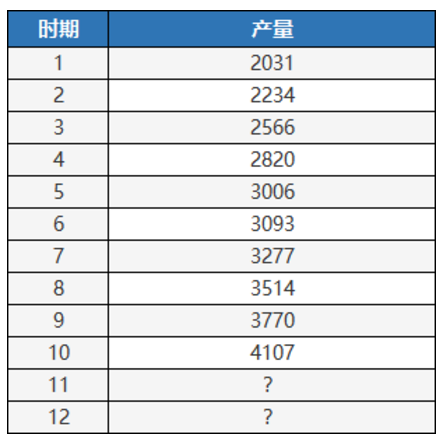


In [9]:
def ExpMove1(y,a):
    '''
    y:时序数据
    a:平滑系数
    '''
    # 获取时序数据长度
    n=len(y)
    # 先创建全0向量
    S1=np.zeros(n)
    S2=np.zeros(n)
    y_pre=np.zeros(n)
    # 设置初始值，S_0^(1) = y0，S_0^(2) = y0
    S1[0]=y[0]
    S2[0]=y[0]
    y_pre[0]=0
    # 循环
    for i in range(1,n):
        # 计算S1和S2
        S1[i]=a*y[i]+(1-a)*S1[i-1]
        S2[i]=a*S1[i]+(1-a)*S2[i-1]
        # 预测值
        y_pre[i] = 2*S1[i-1]-S2[i-1]+a/(1-a)*(S1[i-1]-S2[i-1]) 
    return S1,S2,y_pre
y3 = np.array([2031,2234,2566,2820,3006,3093,3277,3514,3770,4107])
# 计算二次指数平滑
y3e,y3e1,y_pre = ExpMove1(y3,0.3) 
df2 = pd.DataFrame(y3,
                    columns = ['观测值'],
                    index = np.arange(1,11))
df2['一次指数平滑（α=0.3)'] = y3e
df2['二次指数平滑（α=0.3)'] = y3e1
df2['二次指数平滑预测值'] = y_pre
df2

,观测值,一次指数平滑（α=0.3),二次指数平滑（α=0.3),二次指数平滑预测值
1,2031,2031.000000,2031.000000,0.000000
2,2234,2091.900000,2049.270000,2031.000000
3,2566,2234.130000,2104.728000,2152.800000
4,2820,2409.891000,2196.276900,2418.990000
5,3006,2588.723700,2314.010940,2715.054000
6,3093,2740.006590,2441.809635,2981.170500
7,3277,2901.104613,2579.598128,3166.002240
8,3514,3084.973229,2731.210659,3360.399591
9,3770,3290.481260,2898.991839,3590.348330
10,4107,3535.436882,3089.925352,3849.751862


In [10]:
# 计算11、12期预测值
a10 = 2*y3e[-1]-y3e1[-1]
b10 = 0.3/(1-0.3)*(y3e[-1]-y3e1[-1])
T = np.array([1,2])
y10_T = a10+b10*T
print('11、12期预测值为',y10_T)

11、12期预测值为 [4171.88192538 4362.81543832]


$10+T$期的预测值为$\hat{y}_{10+T} = a_{10}+b_{10}*T = 3980.94+190.933*T$


## 5. 小结

本次实验介绍了时间序列预测方法中的移动平均和指数平滑，并通过实际例子基于Python实现预测。

通过本次实验需要掌握以下内容：
- 掌握使用一次移动平均和二次移动平均预测时间序列
- 掌握使用一次指数平滑和二次指数平滑预测时间序列
